In [1]:
import os
import pandas as pd

# Inspect files and subdirectories in your workspace
print("Project files:", os.listdir('.'))

# Check inside the dataset folder if it's nested
for item in os.listdir('.'):
    if os.path.isdir(item) and not item.startswith('.'):
        print(f"Contents of folder '{item}':", os.listdir(item))

Project files: ['BBC News Summary', 'eda_and_preprocessing.ipynb']
Contents of folder 'BBC News Summary': ['BBC News Summary', 'News Articles', 'Summaries']


In [2]:
import os

inner_folder = 'BBC News Summary'
print(f"Contents inside '{inner_folder}':", os.listdir(inner_folder))

# If there is another subfolder inside, let's list it too
for item in os.listdir(inner_folder):
    item_path = os.path.join(inner_folder, item)
    if os.path.isdir(item_path):
        print(f"  -> Subfolder '{item}':", os.listdir(item_path)[:5]) # Show first 5 items

Contents inside 'BBC News Summary': ['BBC News Summary', 'News Articles', 'Summaries']
  -> Subfolder 'BBC News Summary': ['News Articles', 'Summaries']
  -> Subfolder 'News Articles': ['business', 'entertainment', 'politics', 'sport', 'tech']
  -> Subfolder 'Summaries': ['business', 'entertainment', 'politics', 'sport', 'tech']


Total articles loaded: 2225


,file_name,category,text
0,001.txt,business,Ad sales boost Time Warner profit\n\nQuarterly...
1,002.txt,business,Dollar gains on Greenspan speech\n\nThe dollar...
2,003.txt,business,Yukos unit buyer faces loan claim\n\nThe owner...
3,004.txt,business,High fuel prices hit BA's profits\n\nBritish A...
4,005.txt,business,Pernod takeover talk lifts Domecq\n\nShares in...


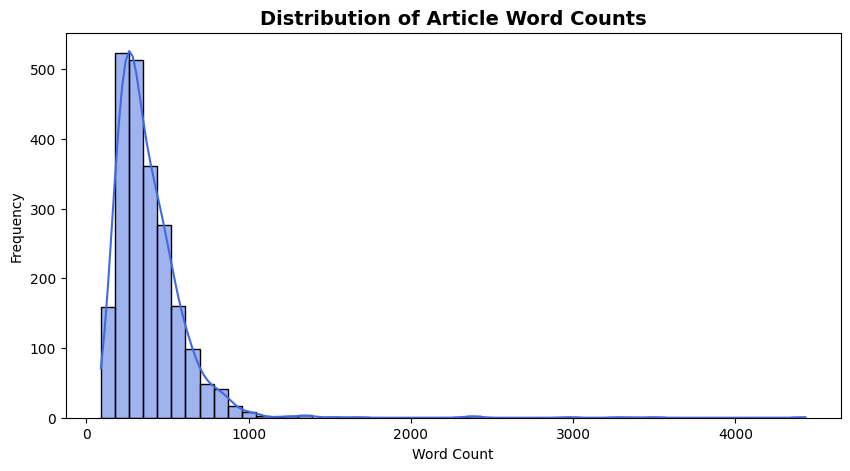

        word_count
count  2225.000000
mean    384.040449
std     238.174497
min      89.000000
25%     246.000000
50%     332.000000
75%     471.000000
max    4432.000000


In [9]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import CountVectorizer

# 1. Function to load articles from the nested folder structure
def load_bbc_dataset(base_dir='BBC News Summary/News Articles'):
    data = []
    categories = ['business', 'entertainment', 'politics', 'sport', 'tech']
    
    for category in categories:
        category_path = os.path.join(base_dir, category)
        if os.path.exists(category_path):
            for file_name in os.listdir(category_path):
                file_path = os.path.join(category_path, file_name)
                if os.path.isfile(file_path):
                    try:
                        with open(file_path, 'r', encoding='utf-8') as f:
                            text = f.read()
                    except UnicodeDecodeError:
                        with open(file_path, 'r', encoding='latin-1') as f:
                            text = f.read()
                    
                    data.append({
                        'file_name': file_name,
                        'category': category,
                        'text': text
                    })
    return pd.DataFrame(data)

# Load the dataset
df = load_bbc_dataset()
print(f"Total articles loaded: {len(df)}")
display(df.head())

# 2. Basic EDA: Text Length Distribution
df['word_count'] = df['text'].apply(lambda x: len(x.split()))

plt.figure(figsize=(10, 5))
sns.histplot(df['word_count'], bins=50, kde=True, color='royalblue')
plt.title('Distribution of Article Word Counts', fontsize=14, fontweight='bold')
plt.xlabel('Word Count')
plt.ylabel('Frequency')
plt.show()

print(df[['word_count']].describe())

C:\Users\DELL\AppData\Local\Temp\ipykernel_1088\4009010124.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Count', y='Word', data=df_unigrams, palette='viridis')


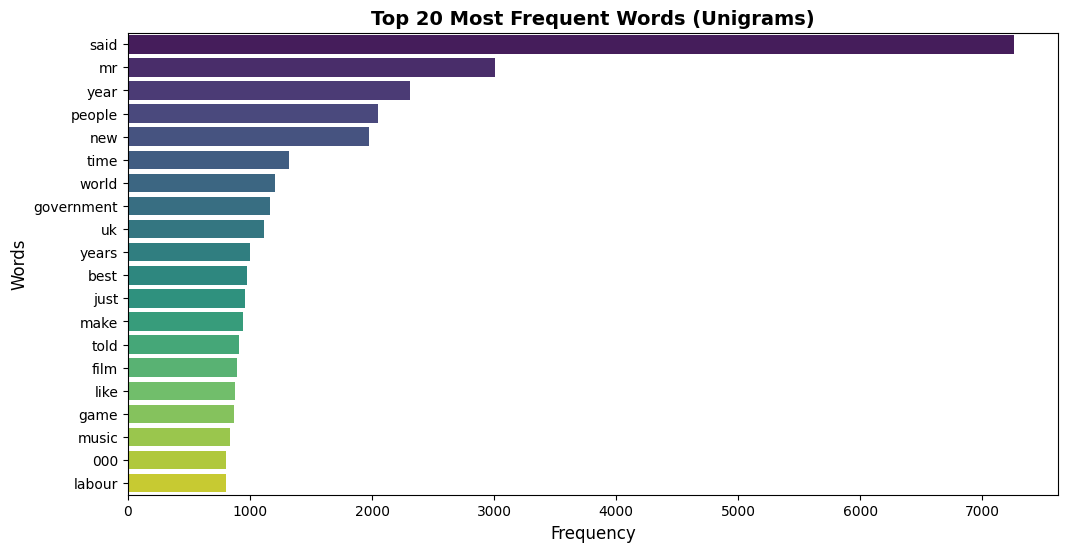

C:\Users\DELL\AppData\Local\Temp\ipykernel_1088\4009010124.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Count', y='Bigram', data=df_bigrams, palette='magma')


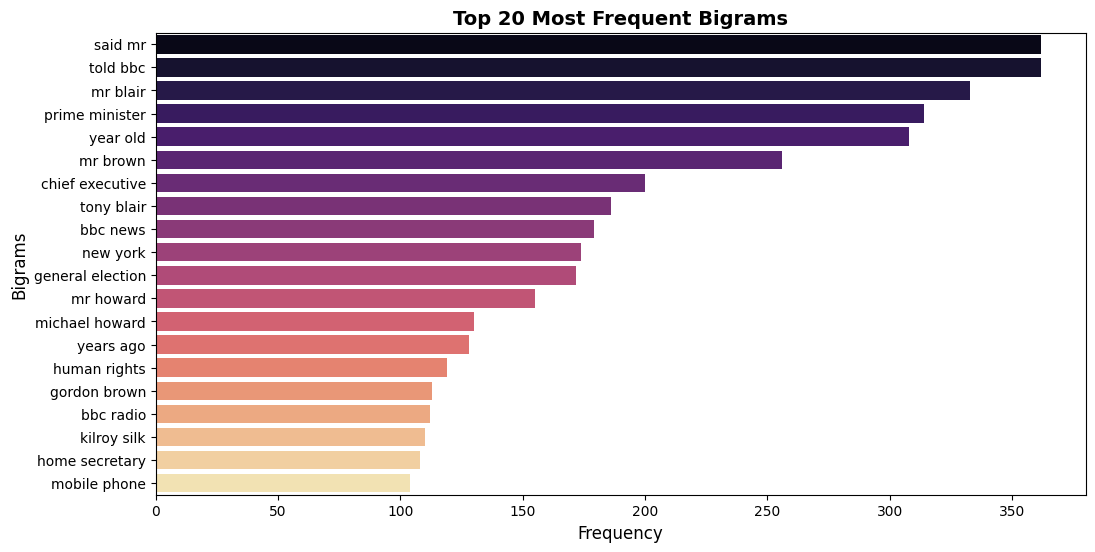

In [10]:
# 3. Keyword and Bigram Analysis using CountVectorizer
def get_top_n_words(corpus, n=20, ngram_range=(1, 1)):
    vec = CountVectorizer(stop_words='english', ngram_range=ngram_range).fit(corpus)
    bag_of_words = vec.transform(corpus)
    sum_words = bag_of_words.sum(axis=0) 
    words_freq = [(word, sum_words[0, idx]) for word, idx in vec.vocabulary_.items()]
    words_freq = sorted(words_freq, key=lambda x: x[1], reverse=True)
    return words_freq[:n]

# Plot Top Unigrams (Keywords)
common_words = get_top_n_words(df['text'], n=20, ngram_range=(1, 1))
df_unigrams = pd.DataFrame(common_words, columns=['Word', 'Count'])

plt.figure(figsize=(12, 6))
sns.barplot(x='Count', y='Word', data=df_unigrams, palette='viridis')
plt.title('Top 20 Most Frequent Words (Unigrams)', fontsize=14, fontweight='bold')
plt.xlabel('Frequency', fontsize=12)
plt.ylabel('Words', fontsize=12)
plt.show()

# Plot Top Bigrams
common_bigrams = get_top_n_words(df['text'], n=20, ngram_range=(2, 2))
df_bigrams = pd.DataFrame(common_bigrams, columns=['Bigram', 'Count'])

plt.figure(figsize=(12, 6))
sns.barplot(x='Count', y='Bigram', data=df_bigrams, palette='magma')
plt.title('Top 20 Most Frequent Bigrams', fontsize=14, fontweight='bold')
plt.xlabel('Frequency', fontsize=12)
plt.ylabel('Bigrams', fontsize=12)
plt.show()

# Train LDA & Generate pyLDAvis Visualization

In [12]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation
import pyLDAvis

# 1. Vectorize text with CountVectorizer
tf_vectorizer = CountVectorizer(max_df=0.95, min_df=2, stop_words='english', max_features=5000)
tf = tf_vectorizer.fit_transform(df['text'])

# 2. Train scikit-learn LDA Model (5 topics for our 5 categories)
n_topics = 5
lda = LatentDirichletAllocation(
    n_components=n_topics, 
    max_iter=10, 
    learning_method='online', 
    learning_offset=50.0, 
    random_state=42
)
lda.fit(tf)

# 3. Helper function to print top words per topic
def print_top_words(model, feature_names, n_top_words):
    for topic_idx, topic in enumerate(model.components_):
        message = f"Topic #{topic_idx + 1}: "
        message += " ".join([feature_names[i] for i in topic.argsort()[:-n_top_words - 1:-1]])
        print(message)

print("\n--- Top Keywords per LDA Topic ---")
tf_feature_names = tf_vectorizer.get_feature_names_out()
print_top_words(lda, tf_feature_names, n_top_words=10)

# 4. Prepare pyLDAvis dashboard using scikit-learn outputs
import numpy as np

# Extract components for pyLDAvis preparation
doc_topic_dists = lda.transform(tf)
topic_term_dists = lda.components_ / lda.components_.sum(axis=1)[:, np.newaxis]
doc_lengths = tf.sum(axis=1).A1
vocab = tf_vectorizer.get_feature_names_out()
term_frequency = tf.sum(axis=0).A1

panel = pyLDAvis.prepare(
    topic_term_dists=topic_term_dists,
    doc_topic_dists=doc_topic_dists,
    doc_lengths=doc_lengths,
    vocab=vocab,
    term_frequency=term_frequency,
    mds='tsne'
)

# Save the interactive HTML visualization
pyLDAvis.save_html(panel, 'lda_visualization.html')
print("\npyLDAvis dashboard successfully trained and saved to 'lda_visualization.html'!")


--- Top Keywords per LDA Topic ---
Topic #1: said mr company court firm club case deal told chief
Topic #2: said year market growth economy sales 2004 china economic new
Topic #3: said mr government people labour election party blair minister new
Topic #4: said year best game film time world win england new
Topic #5: said people mobile technology new music digital net users mr

pyLDAvis dashboard successfully trained and saved to 'lda_visualization.html'!


In [13]:
import joblib

# Save model, vectorizer, and dataset reference
joblib.dump(lda, 'lda_model.pkl')
joblib.dump(tf_vectorizer, 'vectorizer.pkl')
df[['file_name', 'category', 'text']].to_pickle('bbc_processed_df.pkl')

print("Model components and dataframe successfully serialized and saved!")

Model components and dataframe successfully serialized and saved!
